In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("stres.csv")

In [2]:
df.head()

,Sygnatura czasowa,1. Płeć,2. Data urodzenia,3. Wysokość ciała,4. Masa ciała,5. Ile spędza Pani/Pan czasu w pozycji siedzącej podczas pracy?,6. Staż pracy,7. Tryb pracy,8. Jak opisałaby/opisałby Pani/Pan swoje stanowisko pracy?,9. Czy podejmuje Pani/Pan regularną aktywność fizyczną w ciągu tygodnia?,...,"Pytania na tej liście dotyczą Pana/Pani odczuć i myśli z ostatniego miesiąca. Za każdym razem należy wskazać, jak często czuł się Pan i myślał/czuła się Pani i myślała w taki sposób, jak opisano w pytaniu. W tym celu, przy każdym pytaniu, proszę zaznaczyć właściwe pole. [34. Jak często byłeś/byłaś przekonany, że jesteś w stanie poradzić sobie z trudnościami zawodowymi?]","Pytania na tej liście dotyczą Pana/Pani odczuć i myśli z ostatniego miesiąca. Za każdym razem należy wskazać, jak często czuł się Pan i myślał/czuła się Pani i myślała w taki sposób, jak opisano w pytaniu. W tym celu, przy każdym pytaniu, proszę zaznaczyć właściwe pole. [35. Jak często czułeś/czułaś, że wszystko w pracy układa się po Twojej myśli?]","Pytania na tej liście dotyczą Pana/Pani odczuć i myśli z ostatniego miesiąca. Za każdym razem należy wskazać, jak często czuł się Pan i myślał/czuła się Pani i myślała w taki sposób, jak opisano w pytaniu. W tym celu, przy każdym pytaniu, proszę zaznaczyć właściwe pole. [36. Jak często stwierdzałeś/stwierdzałaś, że nie możesz poradzić sobie z wszystkimi obowiązkami zawodowymi?]","Pytania na tej liście dotyczą Pana/Pani odczuć i myśli z ostatniego miesiąca. Za każdym razem należy wskazać, jak często czuł się Pan i myślał/czuła się Pani i myślała w taki sposób, jak opisano w pytaniu. W tym celu, przy każdym pytaniu, proszę zaznaczyć właściwe pole. [37. Jak często byłeś/byłaś w stanie opanować irytację odczuwaną w związku z pracą?]","Pytania na tej liście dotyczą Pana/Pani odczuć i myśli z ostatniego miesiąca. Za każdym razem należy wskazać, jak często czuł się Pan i myślał/czuła się Pani i myślała w taki sposób, jak opisano w pytaniu. W tym celu, przy każdym pytaniu, proszę zaznaczyć właściwe pole. [38. Jak często czułeś/czułaś, że realizacja zadań w pracy przebiega tak, jak zakładałeś/zakładałaś?]","Pytania na tej liście dotyczą Pana/Pani odczuć i myśli z ostatniego miesiąca. Za każdym razem należy wskazać, jak często czuł się Pan i myślał/czuła się Pani i myślała w taki sposób, jak opisano w pytaniu. W tym celu, przy każdym pytaniu, proszę zaznaczyć właściwe pole. [39. Jak często złościłeś/złościłaś się, z powodu braku wpływu na to, co zdarzyło się w pracy?]","Pytania na tej liście dotyczą Pana/Pani odczuć i myśli z ostatniego miesiąca. Za każdym razem należy wskazać, jak często czuł się Pan i myślał/czuła się Pani i myślała w taki sposób, jak opisano w pytaniu. W tym celu, przy każdym pytaniu, proszę zaznaczyć właściwe pole. [40. Jak często czułeś/czułaś, że trudności w pracy mnożą się do tego stopnia, że nie możesz ich przezwyciężyć?]",41.Czy regularnie wykonuje Pani/Pan badanie morfologiczne krwi? (min. 1 raz w roku),42. Czy badała Pani/Pan kiedykolwiek poziom hormonów kory nadnerczy?,43. Jaki był poziom kortyzolu?
0,2026/01/23 1:08:06 PM CET,Kobieta,2002-06-20,164,62,5-6 godzin,1-5 lat,Hybrydowa,Stanowisko menedżerskie / kierownicze (zarządz...,Tak,...,Dość często,Dość często,Dość często,Dość często,Dość często,Dość często,Nigdy,Tak,Nie,NaN
1,2026/01/23 1:08:13 PM CET,Mężczyzna,2001-07-23,189,82,7-8 godzin,1-5 lat,Hybrydowa,Stanowisko specjalistyczne (praca wymagająca w...,Nie,...,Bardzo często,Prawie nigdy,Prawie nigdy,Bardzo często,Bardzo często,Prawie nigdy,Prawie nigdy,Nie,Nie,NaN
2,2026/01/23 1:31:00 PM CET,Kobieta,1998-03-03,156,57,7-8 godzin,1-5 lat,Hybrydowa,Stanowisko menedżerskie / kierownicze (zarządz...,Tak,...,Bardzo często,Czasem,Nigdy,Dość często,Dość często,Nigdy,Nigdy,Tak,Nie,NaN
3,2026/01/23 1:36:13 PM CET,Kobieta,1997-09-02,164,52,ponad 8 godzin,1-5 lat,Hybrydowa,Stanowisko operacyjne / wykonawcze (praca zada...,Nie,...,Dość często,Prawie nigdy,Bardzo często,Bardzo często,Czasem,Bardzo częs

In [3]:
df.loc[df.iloc[:, 9] == 'Nie', df.columns[10:13]] = np.nan

In [4]:
#GAD7
gad_map = {'0 - Wcale': 0, '1 - Przez kilka dni': 1, '2 - Przez ponad połowę dni': 2, '3 - Prawie codziennie': 3}
for col in df.columns[13:20]:
    df[col] = df[col].map(gad_map)
df['GAD7_Score'] = df.iloc[:, 13:20].sum(axis=1)


In [5]:
#gsrs
gsrs_map = {'Brak jakiegokolwiek dyskomfortu': 1, 'Niewielki dyskomfort': 2, 'Umiarkowany dyskomfort': 3, 'Silny dyskomfort': 4, 'Bardzo silny dyskomfort': 5}
for col in df.columns[20:31]:
    df[col] = df[col].map(gsrs_map)
df['GSRS_Score'] = df.iloc[:, 20:31].sum(axis=1)

In [6]:
#stres w pracy
pss_map = {'Nigdy': 0, 'Prawie nigdy': 1, 'Czasem': 2, 'Dość często': 3, 'Bardzo często': 4}
pss_cols = df.columns[31:41]
for col in pss_cols:
    df[col] = df[col].map(pss_map)

In [7]:
for idx in [3, 4, 6, 7]:
    df[pss_cols[idx]] = 4 - df[pss_cols[idx]]
df['Work_Stress_Score'] = df[pss_cols].sum(axis=1)

In [8]:
pos_map = {
    'Stanowisko operacyjne / wykonawcze (praca zadaniowa, powtarzalna, ograniczony wpływ decyzyjny)': 'Operacyjne / wykonawcze',
    'Stanowisko specjalistyczne (praca wymagająca wiedzy merytorycznej, samodzielność, odpowiedzialność za zadania)': 'Specjalistyczne',
    'Stanowisko menedżerskie / kierownicze (zarządzanie zespołem, odpowiedzialność decyzyjna, presja wyników)': 'Menedżerskie / kierownicze',
    'Prezes zarządu ': 'Prezes zarządu'
}

df['Stanowisko'] = df.iloc[:, 8].map(pos_map).fillna(df.iloc[:, 8])

In [9]:
df.head()

,Sygnatura czasowa,1. Płeć,2. Data urodzenia,3. Wysokość ciała,4. Masa ciała,5. Ile spędza Pani/Pan czasu w pozycji siedzącej podczas pracy?,6. Staż pracy,7. Tryb pracy,8. Jak opisałaby/opisałby Pani/Pan swoje stanowisko pracy?,9. Czy podejmuje Pani/Pan regularną aktywność fizyczną w ciągu tygodnia?,...,"Pytania na tej liście dotyczą Pana/Pani odczuć i myśli z ostatniego miesiąca. Za każdym razem należy wskazać, jak często czuł się Pan i myślał/czuła się Pani i myślała w taki sposób, jak opisano w pytaniu. W tym celu, przy każdym pytaniu, proszę zaznaczyć właściwe pole. [38. Jak często czułeś/czułaś, że realizacja zadań w pracy przebiega tak, jak zakładałeś/zakładałaś?]","Pytania na tej liście dotyczą Pana/Pani odczuć i myśli z ostatniego miesiąca. Za każdym razem należy wskazać, jak często czuł się Pan i myślał/czuła się Pani i myślała w taki sposób, jak opisano w pytaniu. W tym celu, przy każdym pytaniu, proszę zaznaczyć właściwe pole. [39. Jak często złościłeś/złościłaś się, z powodu braku wpływu na to, co zdarzyło się w pracy?]","Pytania na tej liście dotyczą Pana/Pani odczuć i myśli z ostatniego miesiąca. Za każdym razem należy wskazać, jak często czuł się Pan i myślał/czuła się Pani i myślała w taki sposób, jak opisano w pytaniu. W tym celu, przy każdym pytaniu, proszę zaznaczyć właściwe pole. [40. Jak często czułeś/czułaś, że trudności w pracy mnożą się do tego stopnia, że nie możesz ich przezwyciężyć?]",41.Czy regularnie wykonuje Pani/Pan badanie morfologiczne krwi? (min. 1 raz w roku),42. Czy badała Pani/Pan kiedykolwiek poziom hormonów kory nadnerczy?,43. Jaki był poziom kortyzolu?,GAD7_Score,GSRS_Score,Work_Stress_Score,Stanowisko
0,2026/01/23 1:08:06 PM CET,Kobieta,2002-06-20,164,62,5-6 godzin,1-5 lat,Hybrydowa,Stanowisko menedżerskie / kierownicze (zarządz...,Tak,...,1,3,0,Tak,Nie,NaN,11,20,18,Menedżerskie / kierownicze
1,2026/01/23 1:08:13 PM CET,Mężczyzna,2001-07-23,189,82,7-8 godzin,1-5 lat,Hybrydowa,Stanowisko specjalistyczne (praca wymagająca w...,Nie,...,0,1,1,Nie,Nie,NaN,9,20,10,Specjalistyczne
2,2026/01/23 1:31:00 PM CET,Kobieta,1998-03-03,156,57,7-8 godzin,1-5 lat,Hybrydowa,Stanowisko menedżerskie / kierownicze (zarządz...,Tak,...,1,0,0,Tak,Nie,NaN,8,16,9,Menedżerskie / kierownicze
3,2026/01/23 1:36:13 PM CET,Kobieta,1997-09-02,164,52,ponad 8 godzin,1-5 lat,Hybrydowa,Stanowisko operacyjne / wykonawcze (praca zada...,Nie,...,2,4,3,Nie,Nie,NaN,13,15,26,Operacyjne / wykonawcze
4,2026/01/23 1:53:56 PM CET,Kobieta,2001-05-05,160,60,7-8 godzin,1-5 lat,Hybrydowa,Stanowisko operacyjne / wykonawcze (praca zada...,Tak,...,3,3,3,Nie,Nie,NaN,16,23,26,Operacyjne / wykonawcze


In [10]:
#korelacja Pearsona
corr_gad_gsrs, p_gad_gsrs = stats.pearsonr(df['GAD7_Score'].dropna(), df['GSRS_Score'].dropna())
corr_work_gsrs, p_work_gsrs = stats.pearsonr(df['Work_Stress_Score'].dropna(), df['GSRS_Score'].dropna())
print("--- WYNIKI KORELACJI ---")
print(f"Korelacja GAD-7 vs GSRS: r = {corr_gad_gsrs:.3f}, p = {p_gad_gsrs:.3f}")
print(f"Korelacja Stres w pracy vs GSRS: r = {corr_work_gsrs:.3f}, p = {p_work_gsrs:.3f}")
table1 = pd.DataFrame({
    "Variable": [
        "1. GAD-7 score",
        "2. Work stress score",
        "3. GSRS score"
    ],
    "1": ["—", "", f"{corr_gad_gsrs:.3f}"],
    "2": ["", "—", f"{corr_work_gsrs:.3f}"],
    "3": ["", "", "—"]
})

print("\nTABLE 1")
print(table1)


--- WYNIKI KORELACJI ---
Korelacja GAD-7 vs GSRS: r = 0.585, p = 0.000
Korelacja Stres w pracy vs GSRS: r = 0.430, p = 0.004

TABLE 1
               Variable      1      2  3
0        1. GAD-7 score      —          
1  2. Work stress score             —   
2         3. GSRS score  0.585  0.430  —


In [11]:
#demografia
# 5. Profil demograficzny
df['Rok_urodzenia'] = pd.to_datetime(df.iloc[:, 2]).dt.year
df['Wiek'] = 2026 - df['Rok_urodzenia']
df['Grupa_wiekowa'] = pd.cut(df['Wiek'], bins=[18, 25, 35, 45, 100], labels=['18-25', '26-35', '36-45', '45+'])

print("\n--- PROFIL BADAWCZY ---")
print("Płeć:\n", df.iloc[:, 1].value_counts())
print("\nGrupy wiekowe:\n", df['Grupa_wiekowa'].value_counts())
print("\nStaż pracy:\n", df.iloc[:, 6].value_counts())
print("\nStanowiska:\n", df.iloc[:, 8].value_counts())




--- PROFIL BADAWCZY ---
Płeć:
 1. Płeć
Kobieta      28
Mężczyzna    15
Name: count, dtype: int64

Grupy wiekowe:
 Grupa_wiekowa
26-35    23
18-25    11
36-45     8
45+       1
Name: count, dtype: int64

Staż pracy:
 6. Staż pracy
1-5 lat         22
11-15 lat        9
6-10 lat         8
ponad 20 lat     3
16-20 lat        1
Name: count, dtype: int64

Stanowiska:
 8. Jak opisałaby/opisałby Pani/Pan swoje stanowisko pracy?
Stanowisko operacyjne / wykonawcze (praca zadaniowa, powtarzalna, ograniczony wpływ decyzyjny)                    21
Stanowisko specjalistyczne (praca wymagająca wiedzy merytorycznej, samodzielność, odpowiedzialność za zadania)    11
Stanowisko menedżerskie / kierownicze (zarządzanie zespołem, odpowiedzialność decyzyjna, presja wyników)          10
Prezes zarządu                                                                                                     1
Name: count, dtype: int64


In [12]:
#krew
col_morfologia = df.columns[41]
col_kortyzol = df.columns[42]

print("\n--- BADANIA KRWI ---")
print("Regularna morfologia:\n", 
      df[col_morfologia].value_counts())
print("\nŚredni poziom stresu (Porównanie: badali kortyzol vs nie badali):")
print(df.groupby(col_kortyzol)[['GAD7_Score',
                                'Work_Stress_Score']].mean())



--- BADANIA KRWI ---
Regularna morfologia:
 41.Czy regularnie wykonuje Pani/Pan badanie morfologiczne krwi? (min. 1 raz w roku)
Tak    31
Nie    12
Name: count, dtype: int64

Średni poziom stresu (Porównanie: badali kortyzol vs nie badali):
                                                    GAD7_Score  \
42. Czy badała Pani/Pan kiedykolwiek poziom hor...               
Nie                                                   8.485714   
Tak                                                   9.000000   

                                                    Work_Stress_Score  
42. Czy badała Pani/Pan kiedykolwiek poziom hor...                     
Nie                                                         16.857143  
Tak                                                         22.375000  


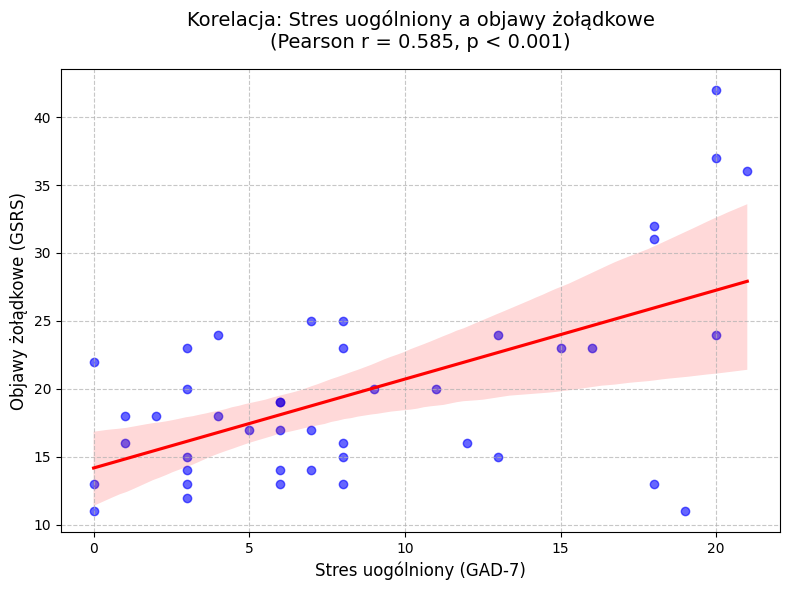

In [13]:
#wykres 1 korelacja GAD7 z GSRS
plt.figure(figsize=(8, 6))
sns.regplot(data=df, x='GAD7_Score', y='GSRS_Score', 
            scatter_kws={'alpha': 0.6, 'color': 'blue'}, 
            line_kws={'color': 'red'})
plt.title('Korelacja: Stres uogólniony a objawy żołądkowe\n(Pearson r = 0.585, p < 0.001)', 
          fontsize=14, pad=15)
plt.xlabel('Stres uogólniony (GAD-7)', fontsize=12)
plt.ylabel('Objawy żołądkowe (GSRS)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('korelacja_stres_gsrs_matplotlib.png', dpi=300)


In [14]:
df.head()

,Sygnatura czasowa,1. Płeć,2. Data urodzenia,3. Wysokość ciała,4. Masa ciała,5. Ile spędza Pani/Pan czasu w pozycji siedzącej podczas pracy?,6. Staż pracy,7. Tryb pracy,8. Jak opisałaby/opisałby Pani/Pan swoje stanowisko pracy?,9. Czy podejmuje Pani/Pan regularną aktywność fizyczną w ciągu tygodnia?,...,41.Czy regularnie wykonuje Pani/Pan badanie morfologiczne krwi? (min. 1 raz w roku),42. Czy badała Pani/Pan kiedykolwiek poziom hormonów kory nadnerczy?,43. Jaki był poziom kortyzolu?,GAD7_Score,GSRS_Score,Work_Stress_Score,Stanowisko,Rok_urodzenia,Wiek,Grupa_wiekowa
0,2026/01/23 1:08:06 PM CET,Kobieta,2002-06-20,164,62,5-6 godzin,1-5 lat,Hybrydowa,Stanowisko menedżerskie / kierownicze (zarządz...,Tak,...,Tak,Nie,NaN,11,20,18,Menedżerskie / kierownicze,2002,24,18-25
1,2026/01/23 1:08:13 PM CET,Mężczyzna,2001-07-23,189,82,7-8 godzin,1-5 lat,Hybrydowa,Stanowisko specjalistyczne (praca wymagająca w...,Nie,...,Nie,Nie,NaN,9,20,10,Specjalistyczne,2001,25,18-25
2,2026/01/23 1:31:00 PM CET,Kobieta,1998-03-03,156,57,7-8 godzin,1-5 lat,Hybrydowa,Stanowisko menedżerskie / kierownicze (zarządz...,Tak,...,Tak,Nie,NaN,8,16,9,Menedżerskie / kierownicze,1998,28,26-35
3,2026/01/23 1:36:13 PM CET,Kobieta,1997-09-02,164,52,ponad 8 godzin,1-5 lat,Hybrydowa,Stanowisko operacyjne / wykonawcze (praca zada...,Nie,...,Nie,Nie,NaN,13,15,26,Operacyjne / wykonawcze,1997,29,26-35
4,2026/01/23 1:53:56 PM CET,Kobieta,2001-05-05,160,60,7-8 godzin,1-5 lat,Hybrydowa,Stanowisko operacyjne / wykonawcze (praca zada...,Tak,...,Nie,Nie,NaN,16,23,26,Operacyjne / wykonawcze,2001,25,18-25


C:\Users\maksk\AppData\Local\Temp\ipykernel_16004\920919899.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot_kort, x=col_kortyzol, y='Work_Stress_Score', palette='Set2')


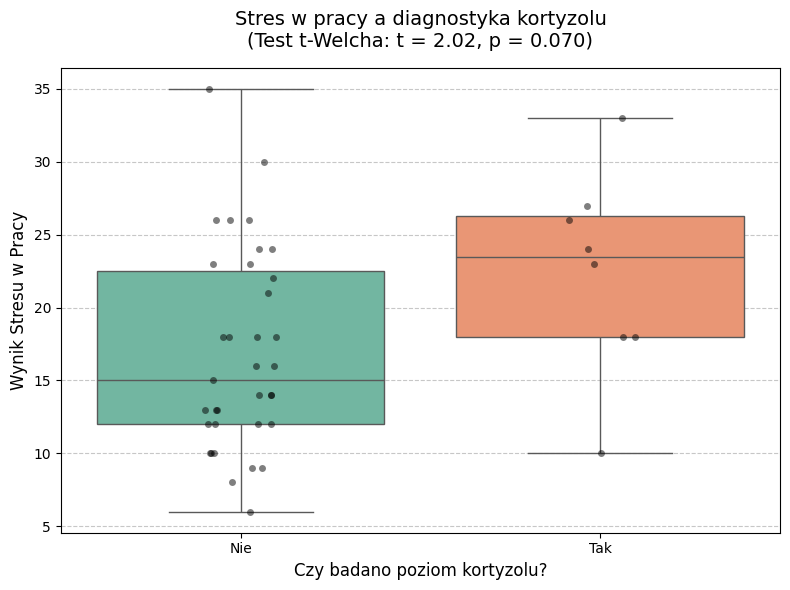

In [15]:
# Wykres 2 stres w pracy a badanie kortyzolu
plt.figure(figsize=(8, 6))
df_plot_kort = df.dropna(subset=[col_kortyzol]).copy()

# OBLICZENIE TESTU T-STUDENTA:
grupa_tak = df_plot_kort[df_plot_kort[col_kortyzol] == 'Tak']['Work_Stress_Score'].dropna()
grupa_nie = df_plot_kort[df_plot_kort[col_kortyzol] == 'Nie']['Work_Stress_Score'].dropna()
t_stat, p_val_t = stats.ttest_ind(grupa_tak, grupa_nie, equal_var=False) # Welch's t-test

sns.boxplot(data=df_plot_kort, x=col_kortyzol, y='Work_Stress_Score', palette='Set2')
sns.stripplot(data=df_plot_kort, x=col_kortyzol, y='Work_Stress_Score', color='black', alpha=0.5, jitter=True)

# Zaktualizowany tytuł z wynikiem testu t-Studenta
plt.title(f'Stres w pracy a diagnostyka kortyzolu\n(Test t-Welcha: t = {t_stat:.2f}, p = {p_val_t:.3f})', 
          fontsize=14, pad=15)

plt.xlabel('Czy badano poziom kortyzolu?', fontsize=12)
plt.ylabel('Wynik Stresu w Pracy', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7, axis='y')
plt.tight_layout()
plt.savefig('stres_kortyzol_matplotlib.png', dpi=300)
plt.show()

In [16]:
#średnia i odchylenie standardowe stanowisk
stats_df = df.groupby('Stanowisko')[['GAD7_Score', 'Work_Stress_Score']].agg(['mean', 'std', 'count'])
order = ['Operacyjne / wykonawcze', 'Specjalistyczne', 'Menedżerskie / kierownicze', 'Prezes zarządu']
rows = []
for pos in order:
    if pos in stats_df.index:
        n = int(stats_df.loc[pos, ('GAD7_Score', 'count')])
        g_m = stats_df.loc[pos, ('GAD7_Score', 'mean')]
        g_sd = stats_df.loc[pos, ('GAD7_Score', 'std')]
        w_m = stats_df.loc[pos, ('Work_Stress_Score', 'mean')]
        w_sd = stats_df.loc[pos, ('Work_Stress_Score', 'std')]
        
        # Zabezpieczenie przed brakiem odchylenia standardowego (n=1)
        g_sd_str = f"{g_sd:.2f}".replace('.', ',') if pd.notna(g_sd) else "-"
        w_sd_str = f"{w_sd:.2f}".replace('.', ',') if pd.notna(w_sd) else "-"
        
        rows.append([
            pos, n, 
            f"{g_m:.2f}".replace('.', ','), g_sd_str, 
            f"{w_m:.2f}".replace('.', ','), w_sd_str
        ])


In [17]:
out = pd.DataFrame(rows, columns=['Stanowisko', 'n', 'GAD-7 M', 'GAD-7 SD', 'Stres w pracy M', 'Stres w pracy SD'])
out.to_csv('tabela_stanowiska_apa.csv', index=False)

In [18]:
df_plot = df.copy()
df_plot['Stanowisko'] = df_plot.iloc[:, 8].map(pos_map).fillna(df_plot.iloc[:, 8])
df_plot['Aktywnosc'] = df_plot.iloc[:, 9]

print("--- Tabela krzyżowa (Liczebność absolutna) ---")
contingency = pd.crosstab(df_plot['Stanowisko'], df_plot['Aktywnosc'])
print(contingency)

print("\n--- Rozkład procentowy w ramach stanowiska ---")
percentages = pd.crosstab(df_plot['Stanowisko'], df_plot['Aktywnosc'], normalize='index') * 100
print(percentages.round(1))

df_filtered = df_plot[df_plot['Stanowisko'] != 'Prezes zarządu'].copy()
contingency_filtered = pd.crosstab(df_filtered['Stanowisko'], df_filtered['Aktywnosc'])
chi2, p, dof, expected = stats.chi2_contingency(contingency_filtered)

print(f"\n--- Wynik Testu Chi-kwadrat (bez Zarządu) ---")
print(f"Chi-kwadrat = {chi2:.3f}, p-value = {p:.3f}")


--- Tabela krzyżowa (Liczebność absolutna) ---
Aktywnosc                   Nie  Tak
Stanowisko                          
Menedżerskie / kierownicze    2    8
Operacyjne / wykonawcze      11   10
Prezes zarządu                1    0
Specjalistyczne               2    9

--- Rozkład procentowy w ramach stanowiska ---
Aktywnosc                     Nie   Tak
Stanowisko                             
Menedżerskie / kierownicze   20.0  80.0
Operacyjne / wykonawcze      52.4  47.6
Prezes zarządu              100.0   0.0
Specjalistyczne              18.2  81.8

--- Wynik Testu Chi-kwadrat (bez Zarządu) ---
Chi-kwadrat = 5.089, p-value = 0.079


<>:22: SyntaxWarning: invalid escape sequence '\c'
<>:22: SyntaxWarning: invalid escape sequence '\c'
C:\Users\maksk\AppData\Local\Temp\ipykernel_16004\1917298497.py:22: SyntaxWarning: invalid escape sequence '\c'
  ax.set_title(f'Aktywność fizyczna a stanowisko pracy\n(Test Chi-kwadrat: $\chi^2$ = {chi2:.2f}, p {p_text})',


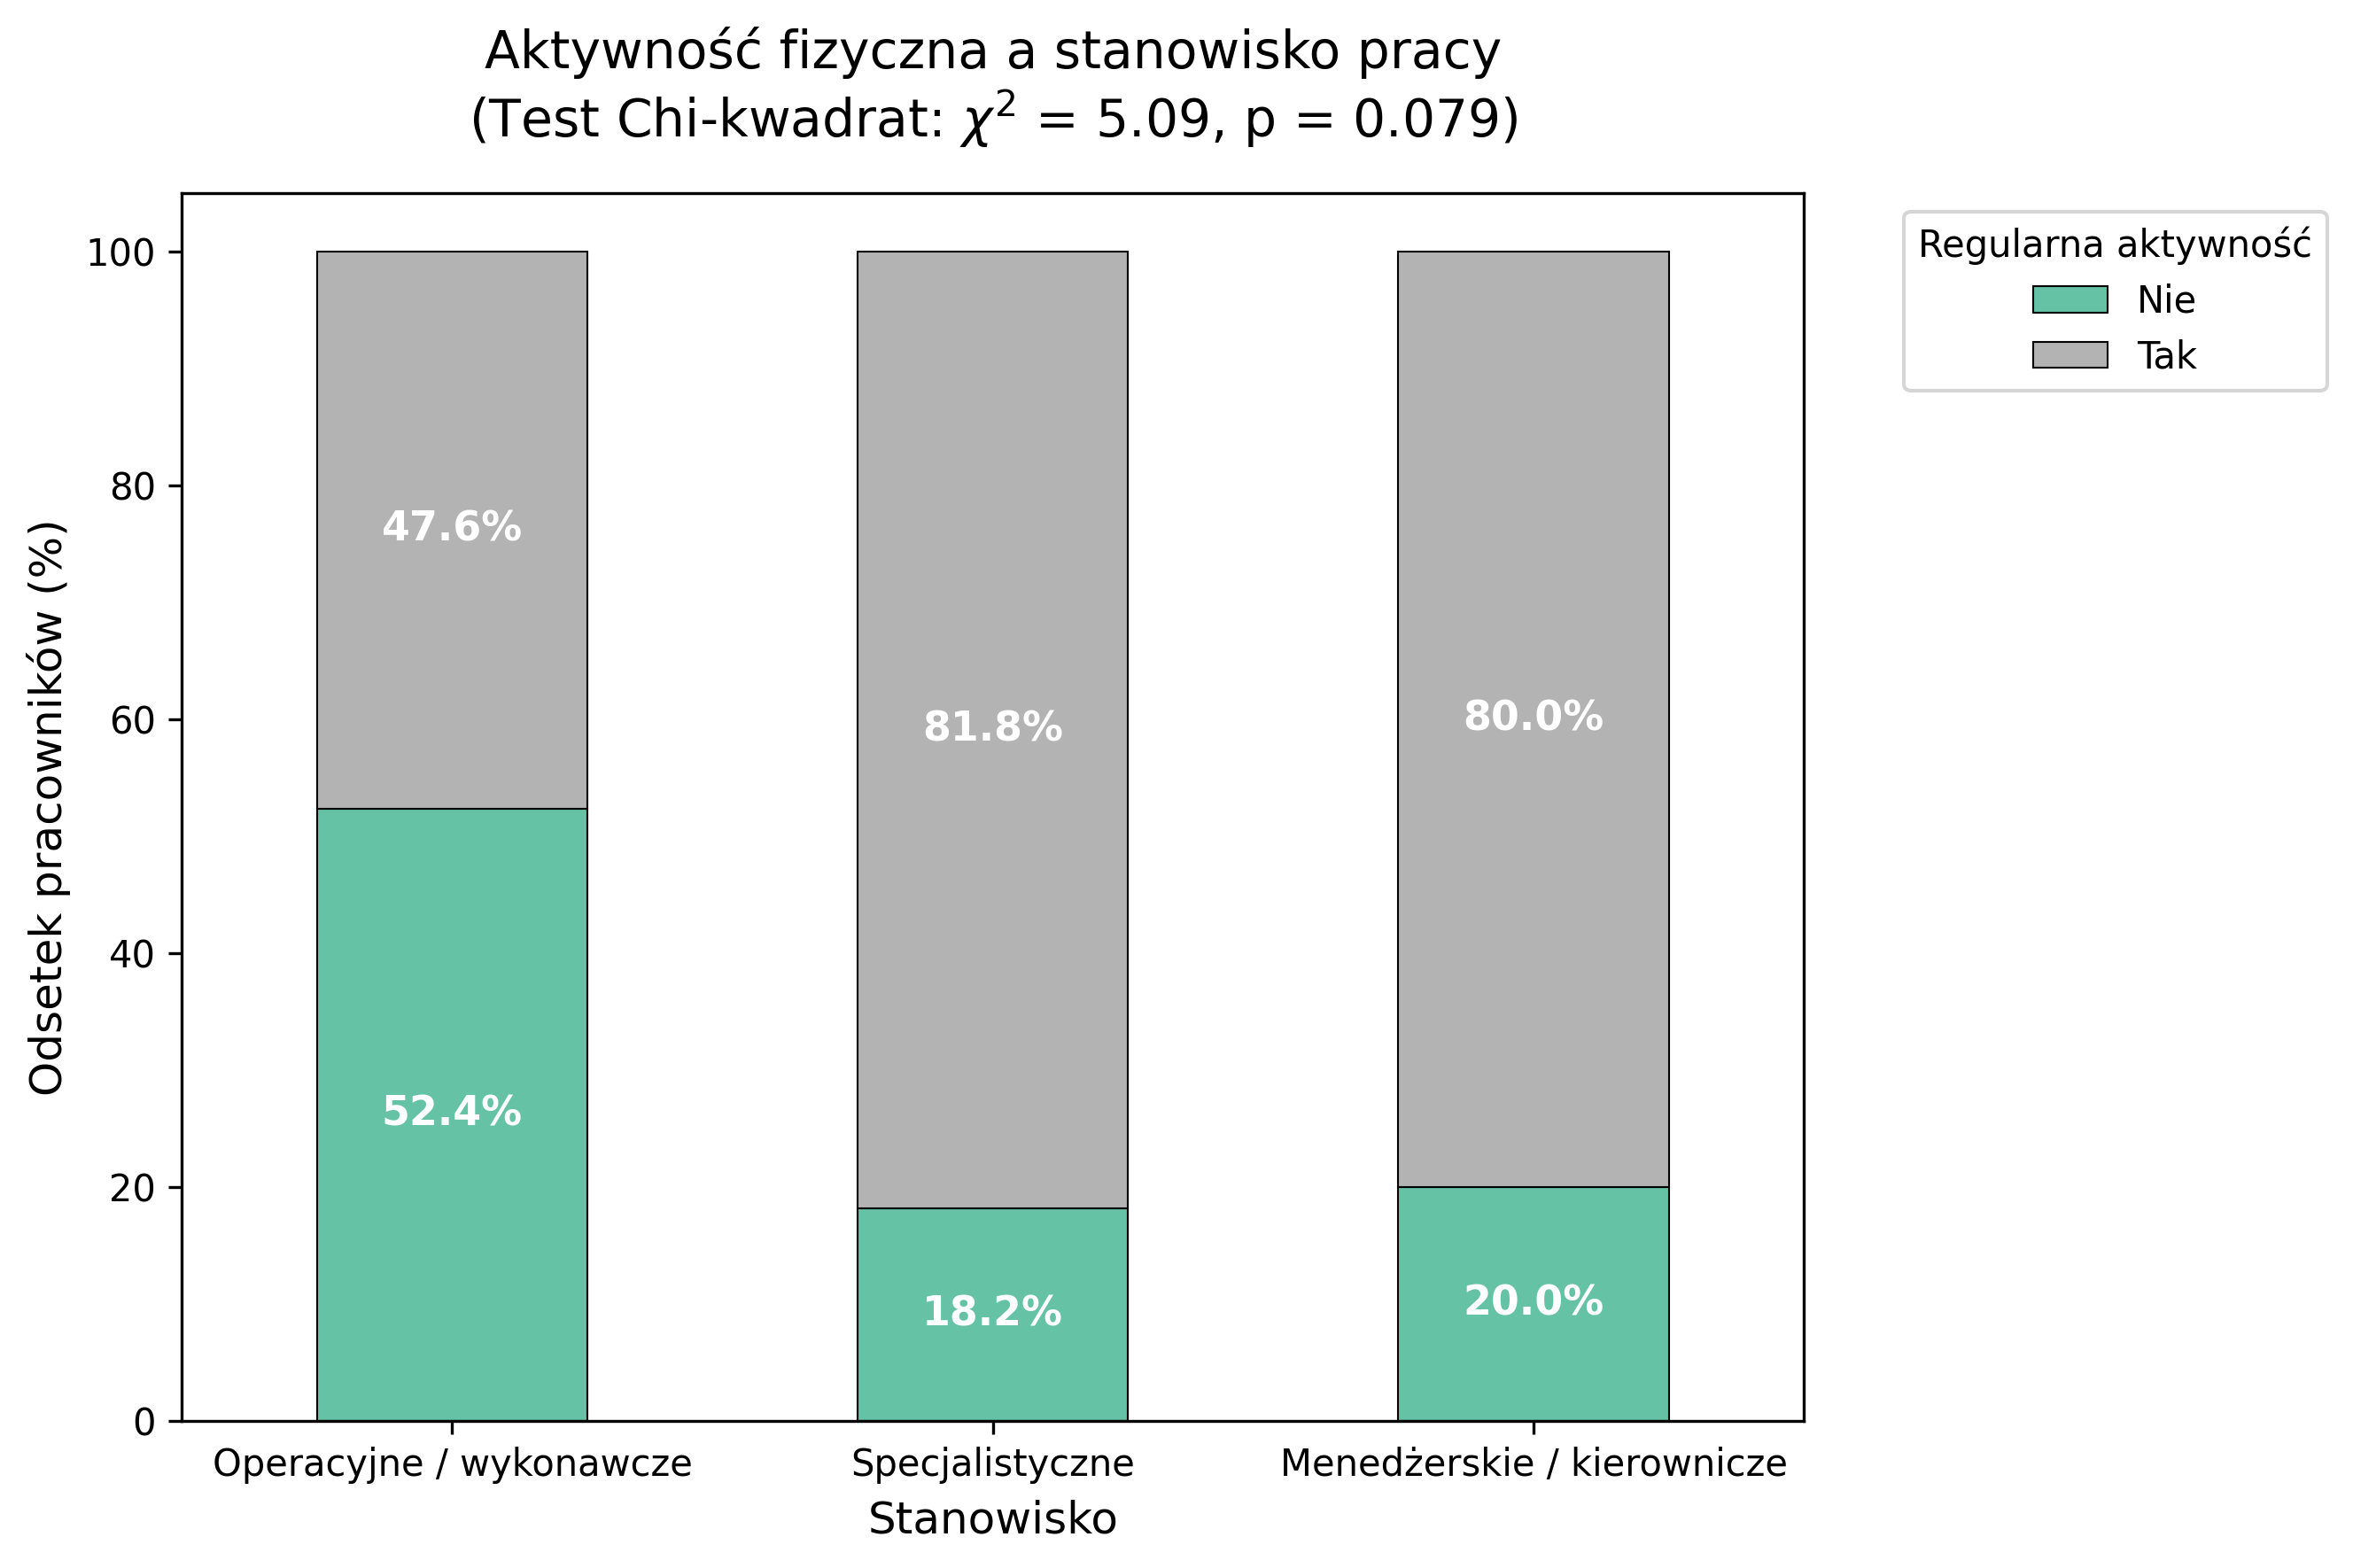

In [19]:
cross_tab = pd.crosstab(df_filtered['Stanowisko'], df_filtered['Aktywnosc'], normalize='index') * 100
order = ['Operacyjne / wykonawcze', 'Specjalistyczne', 'Menedżerskie / kierownicze']
cross_tab = cross_tab.reindex(order)

plt.rcParams['font.family'] = 'DejaVu Sans'
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

cross_tab.plot(kind='bar', stacked=True, colormap='Set2', ax=ax, edgecolor='black', linewidth=0.5)

for c in ax.containers:
    for val in c:
        height = val.get_height()
        if height > 0:  
            ax.annotate(f'{height:.1f}%',
                        xy=(val.get_x() + val.get_width() / 2, val.get_y() + height / 2),
                        xytext=(0, 0),
                        textcoords="offset points",
                        ha='center', va='center', 
                        color='white', fontweight='bold', fontsize=11)

p_text = f"< 0.001" if p < 0.001 else f"= {p:.3f}"
ax.set_title(f'Aktywność fizyczna a stanowisko pracy\n(Test Chi-kwadrat: $\chi^2$ = {chi2:.2f}, p {p_text})', 
             fontsize=14, pad=15)

ax.set_xlabel('Stanowisko', fontsize=12)
ax.set_ylabel('Odsetek pracowników (%)', fontsize=12)
ax.set_xticklabels(order, rotation=0)

ax.legend(title='Regularna aktywność', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('Aktywnosc_fizyczna_v_stanowisko.png', dpi=300)
plt.show()

In [20]:
COL_PLEC = '1. Płeć'
STRESS_COL = 'Work_Stress_Score'


C:\Users\maksk\AppData\Local\Temp\ipykernel_16004\2303078962.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=COL_PLEC, y=STRESS_COL,palette='Pastel2',legend=False)


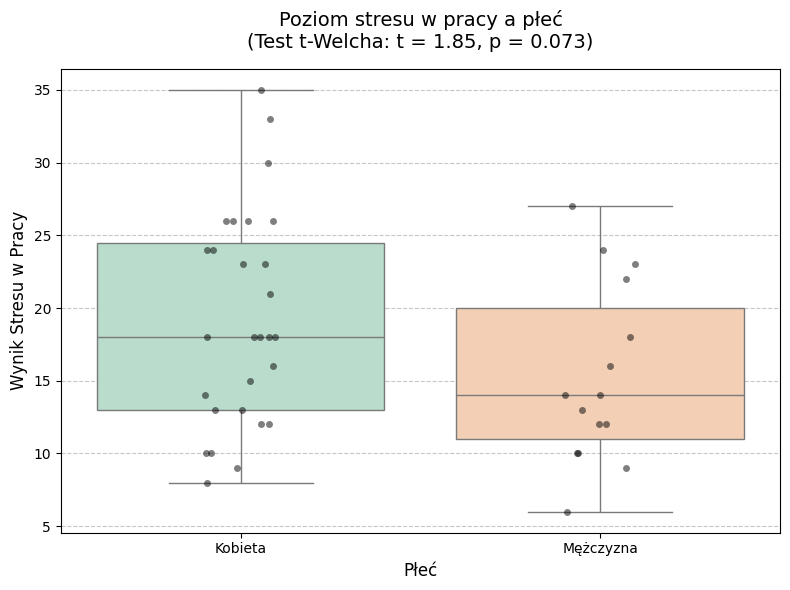

In [21]:
plt.figure(figsize=(8, 6))

# Przygotowanie danych dla płci
grupa_kobiety = df[df[COL_PLEC] == 'Kobieta'][STRESS_COL].dropna()
grupa_mezczyzni = df[df[COL_PLEC] == 'Mężczyzna'][STRESS_COL].dropna()

# Obliczenie testu statystycznego
t_stat_plec, p_val_plec = stats.ttest_ind(grupa_kobiety, grupa_mezczyzni, equal_var=False)

sns.boxplot(data=df, x=COL_PLEC, y=STRESS_COL,palette='Pastel2',legend=False)
sns.stripplot(data=df, x=COL_PLEC, y=STRESS_COL, color='black', alpha=0.5, jitter=True)

plt.title(f'Poziom stresu w pracy a płeć\n(Test t-Welcha: t = {t_stat_plec:.2f}, p = {p_val_plec:.3f})', 
          fontsize=14, pad=15)
plt.xlabel('Płeć', fontsize=12)
plt.ylabel('Wynik Stresu w Pracy', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7, axis='y')
plt.tight_layout()
plt.savefig('stres_plec.png', dpi=300)
plt.show()


C:\Users\maksk\AppData\Local\Temp\ipykernel_16004\2470757416.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_stan, x='Stanowisko', y=STRESS_COL, palette='Pastel2')


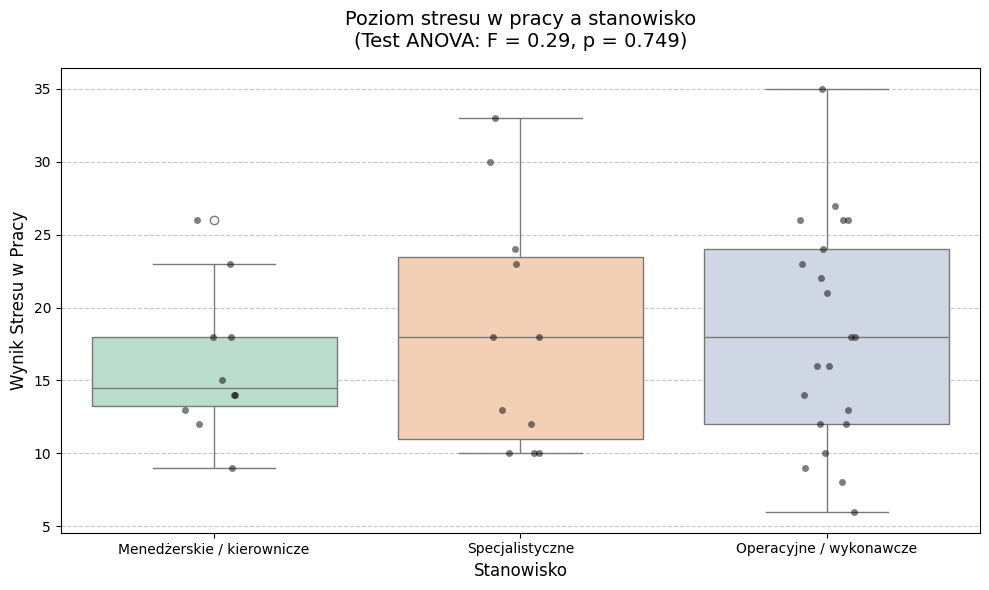

In [22]:
plt.figure(figsize=(10, 6))

# Odrzucamy stanowiska reprezentowane przez 1 osobę (np. Prezes), aby test ANOVA miał sens statystyczny
stanowiska_counts = df['Stanowisko'].value_counts()
valid_stanowiska = stanowiska_counts[stanowiska_counts > 1].index
df_stan = df[df['Stanowisko'].isin(valid_stanowiska)].copy()

# Wyciągamy listy wyników dla poszczególnych stanowisk
grupy_stanowiska = [group[STRESS_COL].dropna() for name, group in df_stan.groupby('Stanowisko')]

# Obliczamy test ANOVA
f_stat, p_val_anova = stats.f_oneway(*grupy_stanowiska)

# Wykres
sns.boxplot(data=df_stan, x='Stanowisko', y=STRESS_COL, palette='Pastel2')
sns.stripplot(data=df_stan, x='Stanowisko', y=STRESS_COL, color='black', alpha=0.5, jitter=True)

plt.title(f'Poziom stresu w pracy a stanowisko\n(Test ANOVA: F = {f_stat:.2f}, p = {p_val_anova:.3f})', 
          fontsize=14, pad=15)
plt.xlabel('Stanowisko', fontsize=12)
plt.ylabel('Wynik Stresu w Pracy', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7, axis='y')
plt.tight_layout()
plt.savefig('stres_stanowisko.png', dpi=300)
plt.show()

In [23]:
COL_PLEC = '1. Płeć'
STRESS_COL = 'GAD7_Score'


C:\Users\maksk\AppData\Local\Temp\ipykernel_16004\3436981355.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=COL_PLEC, y=STRESS_COL,palette='Pastel1',legend=False)


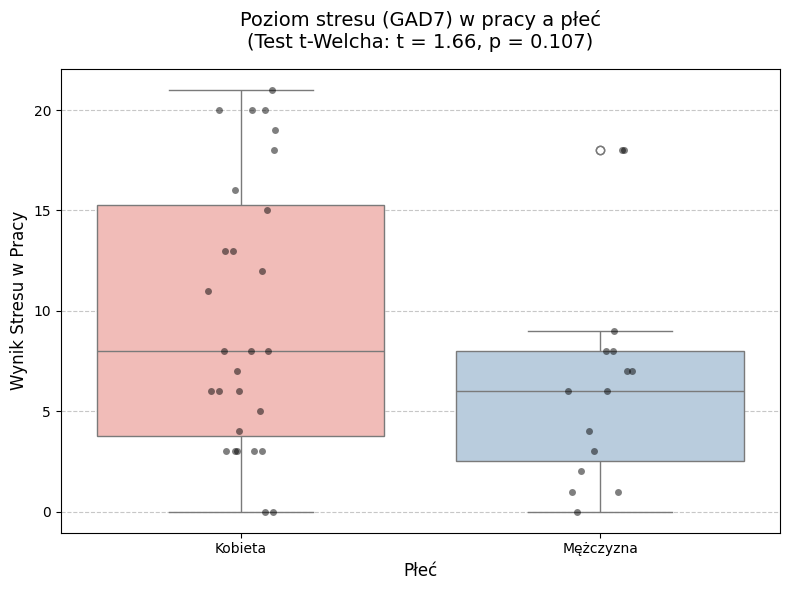

In [24]:
plt.figure(figsize=(8, 6))

# Przygotowanie danych dla płci
grupa_kobiety = df[df[COL_PLEC] == 'Kobieta'][STRESS_COL].dropna()
grupa_mezczyzni = df[df[COL_PLEC] == 'Mężczyzna'][STRESS_COL].dropna()

# Obliczenie testu statystycznego
t_stat_plec, p_val_plec = stats.ttest_ind(grupa_kobiety, grupa_mezczyzni, equal_var=False)

sns.boxplot(data=df, x=COL_PLEC, y=STRESS_COL,palette='Pastel1',legend=False)
sns.stripplot(data=df, x=COL_PLEC, y=STRESS_COL, color='black', alpha=0.5, jitter=True)

plt.title(f'Poziom stresu (GAD7) w pracy a płeć\n(Test t-Welcha: t = {t_stat_plec:.2f}, p = {p_val_plec:.3f})', 
          fontsize=14, pad=15)
plt.xlabel('Płeć', fontsize=12)
plt.ylabel('Wynik Stresu w Pracy', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7, axis='y')
plt.tight_layout()
plt.savefig('stres(GAD7)_plec.png', dpi=300)
plt.show()


C:\Users\maksk\AppData\Local\Temp\ipykernel_16004\1644541657.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_stan, x='Stanowisko', y=STRESS_COL, palette='Pastel1')


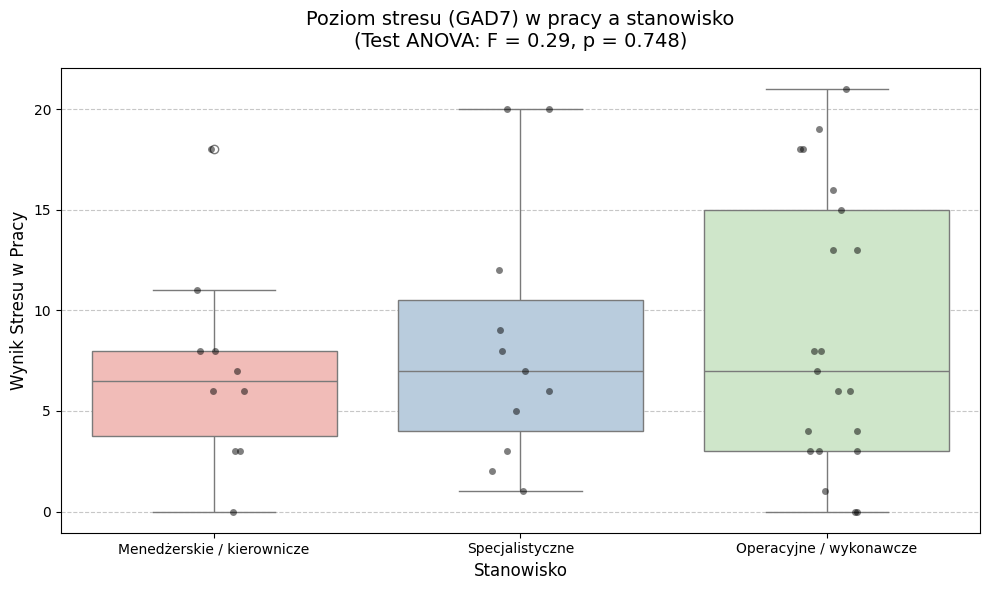

In [25]:
plt.figure(figsize=(10, 6))

# Odrzucamy stanowiska reprezentowane przez 1 osobę (np. Prezes), aby test ANOVA miał sens statystyczny
stanowiska_counts = df['Stanowisko'].value_counts()
valid_stanowiska = stanowiska_counts[stanowiska_counts > 1].index
df_stan = df[df['Stanowisko'].isin(valid_stanowiska)].copy()

# Wyciągamy listy wyników dla poszczególnych stanowisk
grupy_stanowiska = [group[STRESS_COL].dropna() for name, group in df_stan.groupby('Stanowisko')]

# Obliczamy test ANOVA
f_stat, p_val_anova = stats.f_oneway(*grupy_stanowiska)

# Wykres
sns.boxplot(data=df_stan, x='Stanowisko', y=STRESS_COL, palette='Pastel1')
sns.stripplot(data=df_stan, x='Stanowisko', y=STRESS_COL, color='black', alpha=0.5, jitter=True)

plt.title(f'Poziom stresu (GAD7) w pracy a stanowisko\n(Test ANOVA: F = {f_stat:.2f}, p = {p_val_anova:.3f})', 
          fontsize=14, pad=15)
plt.xlabel('Stanowisko', fontsize=12)
plt.ylabel('Wynik Stresu w Pracy', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7, axis='y')
plt.tight_layout()
plt.savefig('stres(GAD7)_stanowisko.png', dpi=300)
plt.show()

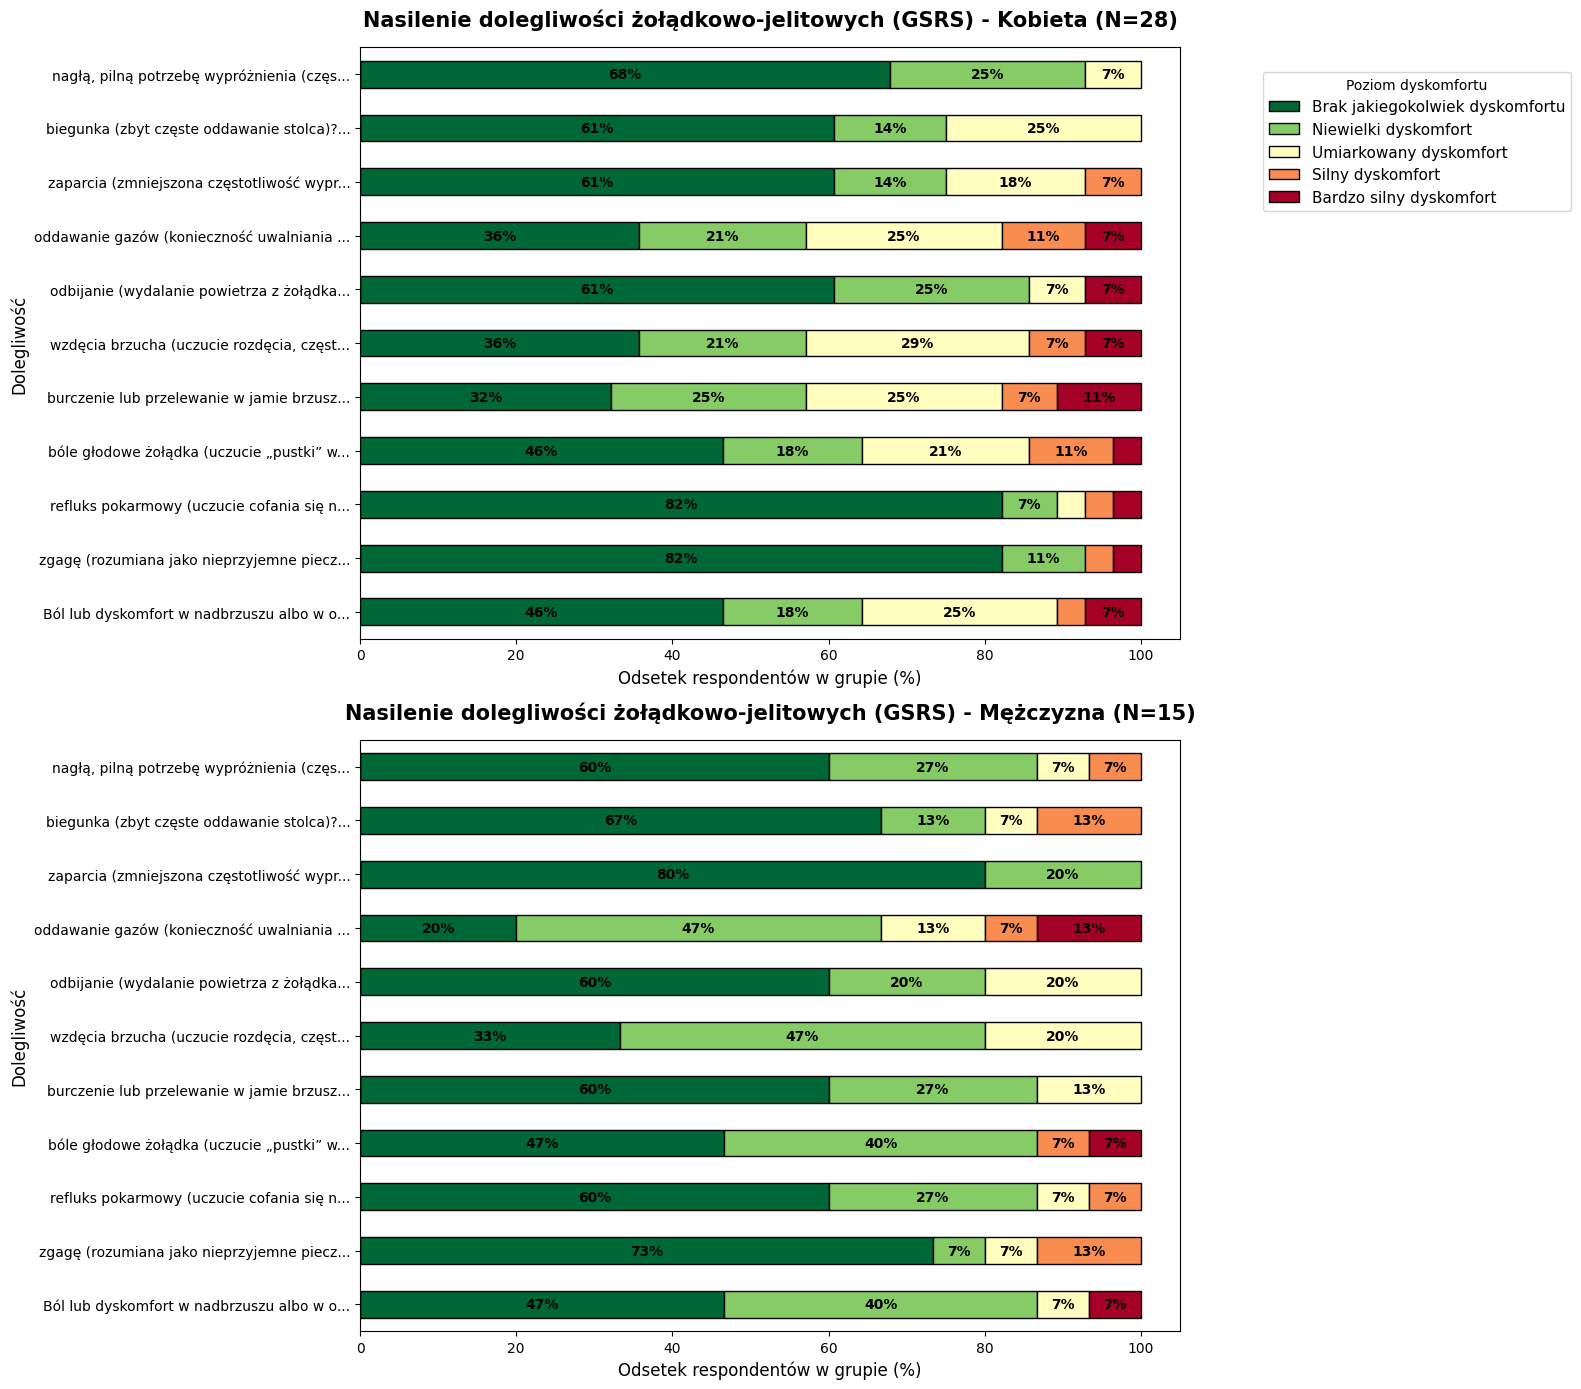

In [32]:
gsrs_cols = df.columns[20:31]

# Skrócone nazwy objawów dla lepszej czytelności osi Y
short_names = []
for col in gsrs_cols:
    if '.' in col:
        short_names.append(col.split('.')[-1].strip()[:40] + '...')
    else:
        short_names.append(col[:40] + '...')

# Skale odpowiedzi
scale_names = [
    "Brak jakiegokolwiek dyskomfortu",
    "Niewielki dyskomfort",
    "Umiarkowany dyskomfort",
    "Silny dyskomfort",
    "Bardzo silny dyskomfort"
]
scale_values = [1, 2, 3, 4, 5]


plec_kategorie = ['Kobieta', 'Mężczyzna']

# Tworzymy figurę z dwoma podwykresami (2 wiersze, 1 kolumna)
fig, axes = plt.subplots(2, 1, figsize=(12, 14))

for idx, plec in enumerate(plec_kategorie):
    # Filtrowanie danych dla danej płci
    df_filtered = df[df[COL_PLEC] == plec]
    
    summary = []
    for i, col in enumerate(gsrs_cols):
        counts = df_filtered[col].value_counts()
        row = {'Objaw': short_names[i]}
        
        for j, num_val in enumerate(scale_values):
            tekstowa_nazwa = scale_names[j]
            row[tekstowa_nazwa] = counts.get(num_val, 0)
            
        summary.append(row)
    df_summary = pd.DataFrame(summary)
    df_summary.set_index('Objaw', inplace=True)
    
    # Przeliczenie na procenty względem liczebności grupy
    df_summary_pct = df_summary.div(df_summary.sum(axis=1), axis=0) * 100
    
    # Rysowanie wykresu w odpowiednim podwykresie
    ax = df_summary_pct.plot(kind='barh', stacked=True, colormap='RdYlGn_r', 
                             edgecolor='black', ax=axes[idx], legend=False)
    
    axes[idx].set_title(f'Nasilenie dolegliwości żołądkowo-jelitowych (GSRS) - {plec} (N={len(df_filtered)})', 
                        fontsize=15, pad=15, fontweight='bold')
    axes[idx].set_xlabel('Odsetek respondentów w grupie (%)', fontsize=12)
    axes[idx].set_ylabel('Dolegliwość', fontsize=12)
    
    # Dodanie etykiet procentowych na paskach
    for c in ax.containers:
        for val in c:
            width = val.get_width()
            if width > 4: # Ukrywamy etykiety dla fragmentów < 4% by zapobiec nachodzeniu się tekstu
                ax.annotate(f'{width:.0f}%',
                            xy=(val.get_x() + width / 2, val.get_y() + val.get_height() / 2),
                            ha='center', va='center',
                            color='black', fontsize=10, fontweight='bold')

# Dodanie jednej wspólnej legendy poza wykresem
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='Poziom dyskomfortu', bbox_to_anchor=(1.05, 0.95), loc='upper left', fontsize=11)

plt.tight_layout()
plt.savefig('gsrs_plec_porownanie.png', dpi=300, bbox_inches='tight')
plt.show()

In [28]:
df.head()

,Sygnatura czasowa,1. Płeć,2. Data urodzenia,3. Wysokość ciała,4. Masa ciała,5. Ile spędza Pani/Pan czasu w pozycji siedzącej podczas pracy?,6. Staż pracy,7. Tryb pracy,8. Jak opisałaby/opisałby Pani/Pan swoje stanowisko pracy?,9. Czy podejmuje Pani/Pan regularną aktywność fizyczną w ciągu tygodnia?,...,41.Czy regularnie wykonuje Pani/Pan badanie morfologiczne krwi? (min. 1 raz w roku),42. Czy badała Pani/Pan kiedykolwiek poziom hormonów kory nadnerczy?,43. Jaki był poziom kortyzolu?,GAD7_Score,GSRS_Score,Work_Stress_Score,Stanowisko,Rok_urodzenia,Wiek,Grupa_wiekowa
0,2026/01/23 1:08:06 PM CET,Kobieta,2002-06-20,164,62,5-6 godzin,1-5 lat,Hybrydowa,Stanowisko menedżerskie / kierownicze (zarządz...,Tak,...,Tak,Nie,NaN,11,20,18,Menedżerskie / kierownicze,2002,24,18-25
1,2026/01/23 1:08:13 PM CET,Mężczyzna,2001-07-23,189,82,7-8 godzin,1-5 lat,Hybrydowa,Stanowisko specjalistyczne (praca wymagająca w...,Nie,...,Nie,Nie,NaN,9,20,10,Specjalistyczne,2001,25,18-25
2,2026/01/23 1:31:00 PM CET,Kobieta,1998-03-03,156,57,7-8 godzin,1-5 lat,Hybrydowa,Stanowisko menedżerskie / kierownicze (zarządz...,Tak,...,Tak,Nie,NaN,8,16,9,Menedżerskie / kierownicze,1998,28,26-35
3,2026/01/23 1:36:13 PM CET,Kobieta,1997-09-02,164,52,ponad 8 godzin,1-5 lat,Hybrydowa,Stanowisko operacyjne / wykonawcze (praca zada...,Nie,...,Nie,Nie,NaN,13,15,26,Operacyjne / wykonawcze,1997,29,26-35
4,2026/01/23 1:53:56 PM CET,Kobieta,2001-05-05,160,60,7-8 godzin,1-5 lat,Hybrydowa,Stanowisko operacyjne / wykonawcze (praca zada...,Tak,...,Nie,Nie,NaN,16,23,26,Operacyjne / wykonawcze,2001,25,18-25
